# Cache, quota, and resume

Three things happen behind every query: metadata is cached, requests are spaced so the
service's quota lasts, and a query that fails partway keeps what it fetched. This
notebook shows each one against NWIS.

In [1]:
from water_ogcapi import NWIS, configure_logger

nwis = NWIS()

## A cache hit

At the DEBUG level the package logs every request it sends. The first `collections()`
call fetches `/collections`; the second is served from the cache, so it logs nothing.
Entries last an hour and are then revalidated with `ETag` or `Last-Modified`.

In [2]:
configure_logger(level="DEBUG")
first = nwis.collections()
second = nwis.collections()
print(len(first.collections or ()), "collections, the same both times:", first == second)

DEBUG    GET https://api.waterdata.usgs.gov/ogcapi/v1/collections?f=json returned HTTP 200 after 1 attempt(s)


39 collections, the same both times: True


`refresh()` drops the cache, so the next call requests the collections again.

In [3]:
nwis.refresh()
_ = nwis.collections()
configure_logger()

DEBUG    waiting 0.6 s for the service's rate limit


DEBUG    GET https://api.waterdata.usgs.gov/ogcapi/v1/collections?f=json returned HTTP 200 after 1 attempt(s)


## The quota governor

Each NWIS response carries the key's quota in `X-RateLimit-Limit` and
`X-RateLimit-Remaining`, and every `Page` keeps them.

In [4]:
DC = (-77.12, 38.80, -76.91, 38.99)
pages = nwis.iter_pages("monitoring-locations", bbox=DC, params={"limit": "1"})
page = next(pages)
pages.close()
print({k: v for k, v in page.headers.items() if k.startswith("x-ratelimit")})

{'x-ratelimit-limit': '3000', 'x-ratelimit-remaining': '2977'}


The service's `Governor` reads those counts. While more than an eighth of the quota is
left, requests start back to back; below that, it spaces their starts further apart
as the quota runs down, up to 60 s. NWIS counts its quota over an hour, so the same
`Governor` with a one-minute window and a quota of 100 shows the effect in seconds.
Each step reports a response with fewer requests left, then times the wait before the
next request may start.

In [5]:
import time

from water_ogcapi import Governor

governor = Governor(window=60.0)
await governor.wait()  # the first request never waits
waits = {}
for remaining in (40, 20, 14, 12, 10, 8, 6):
    governor.observe(200, {"x-ratelimit-limit": "100", "x-ratelimit-remaining": str(remaining)})
    start = time.monotonic()
    await governor.wait()
    waits[remaining] = time.monotonic() - start
{left: round(wait, 1) for left, wait in waits.items()}

{40: 0.0, 20: 0.0, 14: 0.0, 12: 0.2, 10: 1.2, 8: 2.7, 6: 5.2}

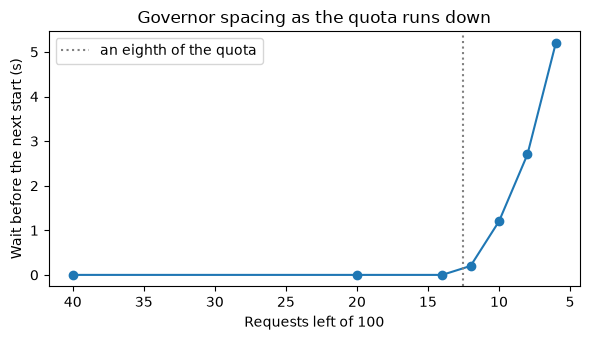

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(waits), list(waits.values()), marker="o")
ax.axvline(100 / 8, color="gray", linestyle=":", label="an eighth of the quota")
ax.invert_xaxis()
ax.set(xlabel="Requests left of 100", ylabel="Wait before the next start (s)")
ax.set(title="Governor spacing as the quota runs down")
ax.legend()
fig.tight_layout()

## Resume after a failure

A transport that answers one `/items` request with a 503 stands in for an outage. With
retries off, the query fails partway: `collect()` raises `PartialResultsError`, whose
`result` holds the pages that arrived and a checkpoint of the requests still to send.

In [7]:
import httpx2

from water_ogcapi import Transport
from water_ogcapi.exceptions import PartialResultsError


class FailOnce(httpx2.AsyncBaseTransport):
    """Answer the second `/items` request with a 503 and send the rest."""

    def __init__(self) -> None:
        self.network = httpx2.AsyncHTTPTransport(http2=True)
        self.items = 0

    async def handle_async_request(self, request: httpx2.Request) -> httpx2.Response:
        if request.url.path.endswith("/items"):
            self.items += 1
            if self.items == 2:
                return httpx2.Response(503, request=request)
        return await self.network.handle_async_request(request)


QUERY = {
    "monitoring_location_id": "USGS-01646500",
    "parameter_code": "00060",
    "statistic_id": "00003",
    "datetime": "2021-01-01/2025-12-31",
}
flaky = NWIS(transport=Transport(transport=FailOnce(), max_retries=0))
try:
    flaky.collect("daily", params=QUERY, split_datetime="year")
except PartialResultsError as err:
    partial = err.result
    print(err.failures[0].status, "from", err.failures[0].url)
flaky.close()
print(len(partial.geojson["features"]), "days kept from", partial.pagination.page_count, "pages")
print(len(partial.checkpoint.pending), "request(s) left to send")

503 from https://api.waterdata.usgs.gov/ogcapi/v1/collections/daily/items?f=json&limit=10000&monitoring_location_id=USGS-01646500&parameter_code=00060&statistic_id=00003&datetime=2021-01-01T00%3A00%3A00Z%2F2021-12-31T23%3A59%3A59.999999Z
1461 days kept from 4 pages
1 request(s) left to send


`collect(resume=...)` sends only the requests the checkpoint lists, on any `NWIS`
instance, and returns the whole result.

In [8]:
whole = nwis.collect("daily", resume=partial)
print(len(whole.geojson["features"]), "days in", whole.pagination.page_count, "pages")
print(whole.pagination.completeness, whole.pagination.checks)

1826 days in 5 pages
complete ('end_of_links', 'unique_ids')


In [9]:
nwis.close()